## Recap of Last Lecture

- We introduced **Computer Vision**, its applications and why it is hard.
- We saw that replacing the first dense layer of an MLP with a **Conv + MaxPool block** clearly improved accuracy on our clothing images.
- We then built intuition for the CNN components: kernels, channels, padding, stride, pooling and flattening.

## Agenda for this Lecture

Our CNN from last time scored only ~50% on the test set and showed a big gap between training and validation accuracy. In this lecture we fix that by fighting **overfitting**:

1. Modifications in the **Model Pipeline** (architecture, BatchNorm, Dropout, learning-rate schedule, L2 regularization)
2. Modifications in the **Data Pipeline** (data augmentation)

We will improve the model **one change at a time** and measure the effect of each change.

## Class Plan (120 minutes)

| # | Block | Time | Cumulative |
|---|-------|------|-----------|
| 1 | Overfitting overview, setup, data loading | 10 min | 0–10 |
| 2 | Baseline CNN: train, read the curves, diagnose overfitting | 12 min | 10–22 |
| 3 | Model changes #1–#2: deeper network + global average pooling, more epochs | 15 min | 22–37 |
| 4 | Model changes #3–#4: BatchNorm + Dropout, LR scheduler + early stopping | 18 min | 37–55 |
| 5 | **Break** | 5 min | 55–60 |
| 6 | Model change #5: L2 regularization (weight decay) + Quiz 1 | 12 min | 60–72 |
| 7 | Data augmentation: ideas and visual demos + Quiz 2 | 15 min | 72–87 |
| 8 | Data change #6: train with augmentation, evaluate | 12 min | 87–99 |
| 9 | Results comparison, AI infusion, Quiz 3, summary | 10 min | 99–109 |
| – | Buffer for questions / slower training | 11 min | 109–120 |

# Tackling Overfitting

**Overfitting = a model with too much capacity for too little data: it memorizes the training set instead of learning patterns that generalize.** Signs: training accuracy keeps rising while validation accuracy stalls or drops.

Four classic remedies:
1. More data / **data augmentation**
2. A **smaller / better-designed** model (fewer parameters)
3. **Regularizing layers** (BatchNorm, Dropout)
4. **Regularizing the loss/optimizer** (L1/L2 penalty)

> **🤖 AI Infusion (2 min, optional):** ask an AI assistant *why a CNN with ~17 million parameters trained on only ~3,000 images is prone to overfitting*, and how this relates to the bias-variance tradeoff. Does its answer mention the four remedies above?

But first, let's rebuild the baseline from last lecture.

## Setup

We use the same clothing dataset as in the first lecture, opensourced [here](https://github.com/alexeygrigorev/clothing-dataset-small). It has 10 classes and comes pre-split into train / validation / test.

In [ ]:
!gdown https://drive.google.com/uc?id=1XdXz0TKo_KCDRHOMvzV-YtcTx7NPG-jC

Downloading...
From (original): https://drive.google.com/uc?id=1XdXz0TKo_KCDRHOMvzV-YtcTx7NPG-jC
From (redirected): https://drive.google.com/uc?id=1XdXz0TKo_KCDRHOMvzV-YtcTx7NPG-jC&confirm=t&uuid=78e3808d-d47b-4953-bae7-3dc4ddf1fba1
To: /content/clothing-dataset-small.zip
100% 106M/106M [00:03<00:00, 33.1MB/s]


In [ ]:
!unzip -q /content/clothing-dataset-small.zip

In [ ]:
import os, glob, copy, random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.metrics as metrics
%matplotlib inline

!pip install -q torchinfo
from torchinfo import summary

We fix all random seeds (so results are reproducible) and pick the GPU if there is one.

In [ ]:
def set_random_seed(seed=111):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_random_seed(111)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 1. Loading the data (step by step)

**Why not read images from disk every epoch?** The dataset is tiny (~3,500 images). Decoding JPEGs every epoch would be the slowest part of training. Instead we will **resize every image to 128×128 once** and keep everything in memory as a tensor. Then each epoch is fast and we can experiment a lot in one class.

**Step 1 — define the one-time preprocessing:** resize to a fixed size (batches need equal-sized images) and convert to a `uint8` tensor of shape (C, H, W).

In [ ]:
BASE_DIR = "clothing-dataset-small"
IMG_SIZE = 128

resize_only = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.PILToTensor(),   # PIL image (H,W,C) -> uint8 tensor (C,H,W), values 0..255
])

**Step 2 — read each split once** with `ImageFolder` (class = sub-folder name) and stack all images into a single tensor.

In [ ]:
def load_split(split):
    folder = datasets.ImageFolder(f"{BASE_DIR}/{split}", transform=resize_only)
    X = torch.stack([img for img, _ in folder])   # (N, 3, 128, 128) uint8
    y = torch.tensor(folder.targets)              # (N,) integer class ids
    return X, y, folder.classes

X_train, y_train, class_names = load_split("train")
X_val,   y_val,   _           = load_split("validation")
X_test,  y_test,  _           = load_split("test")

print("Classes:", class_names)
print("Train / Val / Test sizes:", len(X_train), len(X_val), len(X_test))
print("Train tensor:", X_train.shape, X_train.dtype)

Classes: ['dress', 'hat', 'longsleeve', 'outwear', 'pants', 'shirt', 'shoes', 'shorts', 'skirt', 't-shirt']
Train / Val / Test sizes: 3068 341 372
Train tensor: torch.Size([3068, 3, 128, 128]) torch.uint8


**Step 3 — wrap the tensors in a `Dataset`.** A PyTorch `Dataset` just needs `__len__` and `__getitem__`. This is also the place where we will plug in **augmentation later** (applied to *training images only*) and where we rescale pixels from 0–255 to 0–1.

In [ ]:
class ClothingDataset(Dataset):
    def __init__(self, X, y, augment=None):
        self.X, self.y, self.augment = X, y, augment

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        img = self.X[idx]                 # uint8 tensor (3,128,128)
        if self.augment is not None:
            img = self.augment(img)       # random augmentation (training only)
        img = img.float() / 255.0         # rescale to [0, 1]
        return img, self.y[idx]

**Step 4 — wrap each dataset in a `DataLoader`** (batching + shuffling). Only the training loader is shuffled.

In [ ]:
def make_loaders(train_augment=None, batch_size=32):
    train_loader = DataLoader(ClothingDataset(X_train, y_train, train_augment), batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(ClothingDataset(X_val, y_val),   batch_size=batch_size)
    test_loader  = DataLoader(ClothingDataset(X_test, y_test), batch_size=batch_size)
    return train_loader, val_loader, test_loader

train_ds, val_ds, test_ds = make_loaders()

images, labels = next(iter(train_ds))
print("One batch:", images.shape, images.dtype, "| min/max:", images.min().item(), images.max().item())

One batch: torch.Size([32, 3, 128, 128]) torch.float32 | min/max: 0.003921568859368563 1.0


## 2. Baseline Model

This is the CNN from the last lecture:
- Problem: image classification, 10 clothing classes
- Model: **one** Conv+ReLU+MaxPool block followed by two dense layers
- Expected result: roughly 50% test accuracy (your run will vary)

Let's define it and look at its parameters.

In [ ]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=10, hidden_size=256):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 64 * 64, hidden_size)   # 128x128 image -> pooled to 64x64, with 16 channels
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))   # (bs, 16, 64, 64)
        x = self.flatten(x)                        # (bs, 65536)
        x = self.relu(self.fc1(x))                 # (bs, 256)
        return self.fc2(x)                         # (bs, 10) raw logits (CrossEntropyLoss applies softmax itself)

model = BaselineCNN().to(device)
summary(model, input_size=(1, 3, 128, 128))

Layer (type:depth-idx)                   Output Shape              Param #
BaselineCNN                              [1, 10]                   --
├─Conv2d: 1-1                            [1, 16, 128, 128]         448
├─ReLU: 1-2                              [1, 16, 128, 128]         --
├─MaxPool2d: 1-3                         [1, 16, 64, 64]           --
├─Flatten: 1-4                           [1, 65536]                --
├─Linear: 1-5                            [1, 256]                  16,777,472
├─ReLU: 1-6                              [1, 256]                  --
├─Linear: 1-7                            [1, 10]                   2,570
Total params: 16,780,490
Trainable params: 16,780,490
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 24.12
Input size (MB): 0.20
Forward/backward pass size (MB): 2.10
Params size (MB): 67.12
Estimated Total Size (MB): 69.42

**Look at the parameter column.** The convolution has only 448 parameters, but `fc1` has 65,536 × 256 + 256 ≈ **16.8 million**. Almost the entire model sits in one dense layer, and we only have ~3,000 training images. Keep this in mind — it is the key clue for the fix.

### Training code, built piece by piece

**Piece 1 — one training epoch.** For every batch: forward pass → loss → backward pass → optimizer step. We also track the running loss and accuracy.

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()                                   # enables training behaviour (Dropout, BatchNorm updates)
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()                       # 1. clear old gradients
        logits = model(x)                           # 2. forward pass
        loss = criterion(logits, y)                 # 3. compute loss
        loss.backward()                             # 4. backpropagate
        optimizer.step()                            # 5. update weights

        total_loss += loss.item() * x.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += x.size(0)
    return total_loss / total, correct / total

**Piece 2 — one evaluation pass.** Same loop, but with no gradients and no weight updates. `model.eval()` switches Dropout off and makes BatchNorm use its stored statistics.

In [ ]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)

        total_loss += loss.item() * x.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += x.size(0)
    return total_loss / total, correct / total

**Piece 3 — the `fit` function.** It loops over epochs, records the history, and **remembers the weights with the lowest validation loss** (so we can restore the best model at the end instead of keeping a possibly over-trained last one).

In [ ]:
def fit(model, train_loader, val_loader, epochs=10, lr=1e-3, weight_decay=0.0):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    best_val_loss, best_state = float("inf"), None

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = evaluate(model, val_loader, criterion)

        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[k].append(v)

        if va_loss < best_val_loss:                         # keep the best weights seen so far
            best_val_loss, best_state = va_loss, copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch:>2}/{epochs} - loss: {tr_loss:.4f} - acc: {tr_acc:.4f} "
              f"- val_loss: {va_loss:.4f} - val_acc: {va_acc:.4f}")

    model.load_state_dict(best_state)                        # restore best weights
    return history

**Piece 4 — plotting and test-set reporting helpers** (we will reuse these after every experiment).

In [ ]:
def plot_history(history, title=""):
    epochs = range(1, len(history["accuracy"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))

    ax[0].plot(epochs, [a * 100 for a in history["accuracy"]], "b", label="Train")
    ax[0].plot(epochs, [a * 100 for a in history["val_accuracy"]], "r", label="Val")
    ax[0].set_title(f"Accuracy {title}"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("Accuracy (%)"); ax[0].legend()

    ax[1].plot(epochs, history["loss"], "b", label="Train")
    ax[1].plot(epochs, history["val_loss"], "r", label="Val")
    ax[1].set_title(f"Loss {title}"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("Loss"); ax[1].legend()
    plt.show()

In [ ]:
results = {}   # experiment name -> test accuracy, filled in as we go

@torch.no_grad()
def predict(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for x, y in loader:
        y_pred.append(model(x.to(device)).argmax(dim=1).cpu())
        y_true.append(y)
    return torch.cat(y_true).numpy(), torch.cat(y_pred).numpy()

def report_test(model, name, show_cm=False):
    y_true, y_pred = predict(model, test_ds)
    acc = metrics.accuracy_score(y_true, y_pred) * 100
    results[name] = acc
    print(f"\nTest accuracy [{name}]: {acc:.2f}%")
    if show_cm:
        cm = metrics.confusion_matrix(y_true, y_pred)
        plt.figure(figsize=(9, 7))
        sns.heatmap(cm, annot=True, fmt="g", cmap="YlGnBu", xticklabels=class_names, yticklabels=class_names)
        plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

### Train the baseline (10 epochs)

In [ ]:
set_random_seed(111)
model = BaselineCNN().to(device)
history = fit(model, train_ds, val_ds, epochs=10)

Epoch  1/10 - loss: 2.3983 - acc: 0.3468 - val_loss: 1.7990 - val_acc: 0.3666
Epoch  2/10 - loss: 1.4544 - acc: 0.5346 - val_loss: 1.5469 - val_acc: 0.4897
Epoch  3/10 - loss: 1.1861 - acc: 0.6138 - val_loss: 1.5103 - val_acc: 0.5161
Epoch  4/10 - loss: 0.9448 - acc: 0.6952 - val_loss: 1.3240 - val_acc: 0.5660
Epoch  5/10 - loss: 0.7131 - acc: 0.7800 - val_loss: 1.4022 - val_acc: 0.5806
Epoch  6/10 - loss: 0.5012 - acc: 0.8553 - val_loss: 1.4666 - val_acc: 0.5455
Epoch  7/10 - loss: 0.3055 - acc: 0.9302 - val_loss: 1.3664 - val_acc: 0.5748
Epoch  8/10 - loss: 0.1903 - acc: 0.9641 - val_loss: 1.5507 - val_acc: 0.5572
Epoch  9/10 - loss: 0.1176 - acc: 0.9827 - val_loss: 1.5692 - val_acc: 0.6041
Epoch 10/10 - loss: 0.0721 - acc: 0.9925 - val_loss: 1.6500 - val_acc: 0.5865


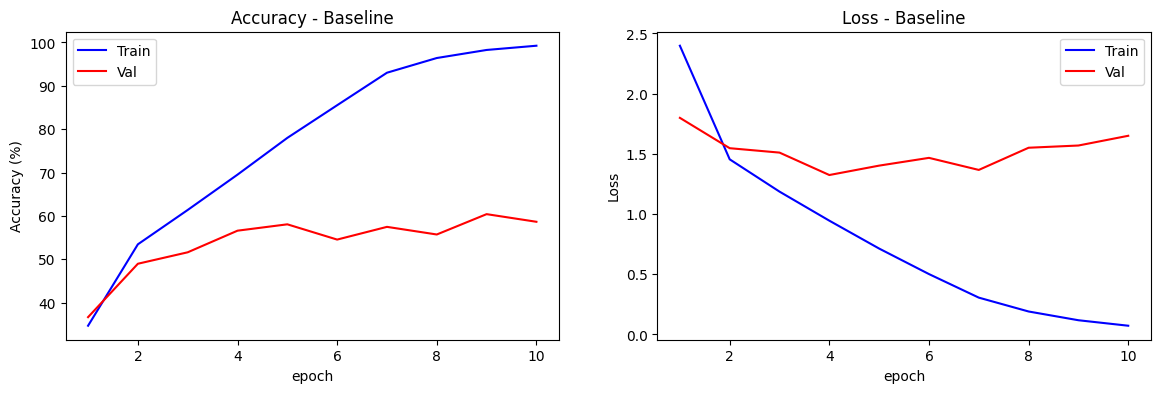


Test accuracy [Baseline CNN]: 47.58%


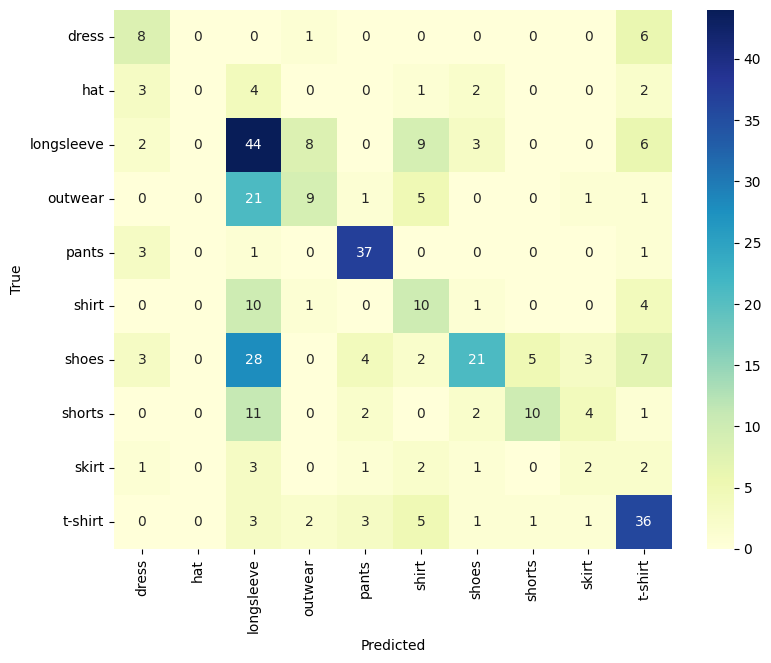

In [ ]:
plot_history(history, "- Baseline")
report_test(model, "Baseline CNN", show_cm=True)

#### What is the most apparent issue in these plots?

**Training accuracy keeps climbing while validation accuracy stalls, and validation loss turns upward** — that is **overfitting**. The model memorizes the 3,000 training images instead of learning general clothing features.

**Where does the overfitting come from?** Overfitting = *many trainable parameters, few training samples.* Remember the summary: one dense layer holds ~16.8M of the parameters.

## 3. Modifications in the Model Pipeline

Simply removing layers would hurt performance — the network is already small. The real problem is the huge Flatten → Dense connection. So:

### Modification #1: a deeper feature extractor + Global Average Pooling

- **Go deeper.** Stack more Conv+ReLU+MaxPool blocks. Each block halves the image size (128 → 64 → 32 → 16 → 8) while the number of channels grows (16 → 32 → 64 → 128 → 256). Later layers see larger parts of the image and learn richer features.
- **Replace Flatten with Global Average Pooling (GAP).** Instead of unrolling an 8×8×256 map into 16,384 numbers (which would need 16,384 × 256 ≈ 4.2M weights in the next dense layer), GAP simply **averages each channel's 8×8 map into one number**, giving 256 numbers. The next dense layer then needs only 256 × 256 ≈ 65K weights.

Let's build this step by step. **First, a small helper that builds one block:**

In [ ]:
def conv_block(in_ch, out_ch, use_bn=False, pool=True):
    """Conv -> (BatchNorm) -> ReLU -> (MaxPool)"""
    layers = [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)]
    if use_bn:
        layers.append(nn.BatchNorm2d(out_ch))
    layers.append(nn.ReLU())
    if pool:
        layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

**Now the full network.** The two flags `use_bn` and `dropout` are switched off for now; we will switch them on in Modification #3. That way, *every later experiment uses the same architecture code* and differences in results come only from what we change.

In [ ]:
class CNN(nn.Module):
    def __init__(self, num_classes=10, hidden_size=256, use_bn=False, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3,   16,  use_bn),               # 128 -> 64
            conv_block(16,  32,  use_bn),               # 64  -> 32
            conv_block(32,  64,  use_bn),               # 32  -> 16
            conv_block(64,  128, use_bn),               # 16  -> 8
            conv_block(128, 256, use_bn, pool=False),   # stays 8x8
            nn.AdaptiveAvgPool2d(1),                    # Global Average Pooling: (bs,256,8,8) -> (bs,256,1,1)
            nn.Flatten(),                               # -> (bs,256)
        )
        head = [nn.Linear(256, hidden_size)]
        if use_bn:
            head.append(nn.BatchNorm1d(hidden_size))
        head += [nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden_size, num_classes)]
        self.head = nn.Sequential(*head)

    def forward(self, x):
        return self.head(self.features(x))

In [ ]:
set_random_seed(111)
model = CNN().to(device)
summary(model, input_size=(1, 3, 128, 128))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [1, 10]                   --
├─Sequential: 1-1                        [1, 256]                  --
│    └─Sequential: 2-1                   [1, 16, 64, 64]           --
│    │    └─Conv2d: 3-1                  [1, 16, 128, 128]         448
│    │    └─ReLU: 3-2                    [1, 16, 128, 128]         --
│    │    └─MaxPool2d: 3-3               [1, 16, 64, 64]           --
│    └─Sequential: 2-2                   [1, 32, 32, 32]           --
│    │    └─Conv2d: 3-4                  [1, 32, 64, 64]           4,640
│    │    └─ReLU: 3-5                    [1, 32, 64, 64]           --
│    │    └─MaxPool2d: 3-6               [1, 32, 32, 32]           --
│    └─Sequential: 2-3                   [1, 64, 16, 16]           --
│    │    └─Conv2d: 3-7                  [1, 64, 32, 32]           18,496
│    │    └─ReLU: 3-8                    [1, 64, 32, 32]           --
│    │ 

The new model has **under 0.5 million parameters** (the baseline had ~16.8M), yet it is much deeper. Let's train it for the same 10 epochs.

Epoch  1/10 - loss: 2.1625 - acc: 0.2314 - val_loss: 2.1636 - val_acc: 0.2375
Epoch  2/10 - loss: 2.1249 - acc: 0.2591 - val_loss: 2.1666 - val_acc: 0.2375
Epoch  3/10 - loss: 2.1159 - acc: 0.2621 - val_loss: 2.1757 - val_acc: 0.2375
Epoch  4/10 - loss: 2.0972 - acc: 0.2647 - val_loss: 2.1404 - val_acc: 0.2434
Epoch  5/10 - loss: 2.0805 - acc: 0.2673 - val_loss: 2.1279 - val_acc: 0.2405
Epoch  6/10 - loss: 2.0757 - acc: 0.2669 - val_loss: 2.1270 - val_acc: 0.2287
Epoch  7/10 - loss: 2.0682 - acc: 0.2650 - val_loss: 2.1112 - val_acc: 0.2405
Epoch  8/10 - loss: 2.0462 - acc: 0.2683 - val_loss: 2.1275 - val_acc: 0.2463
Epoch  9/10 - loss: 2.0462 - acc: 0.2627 - val_loss: 2.1157 - val_acc: 0.2405
Epoch 10/10 - loss: 2.0295 - acc: 0.2689 - val_loss: 2.1074 - val_acc: 0.2405


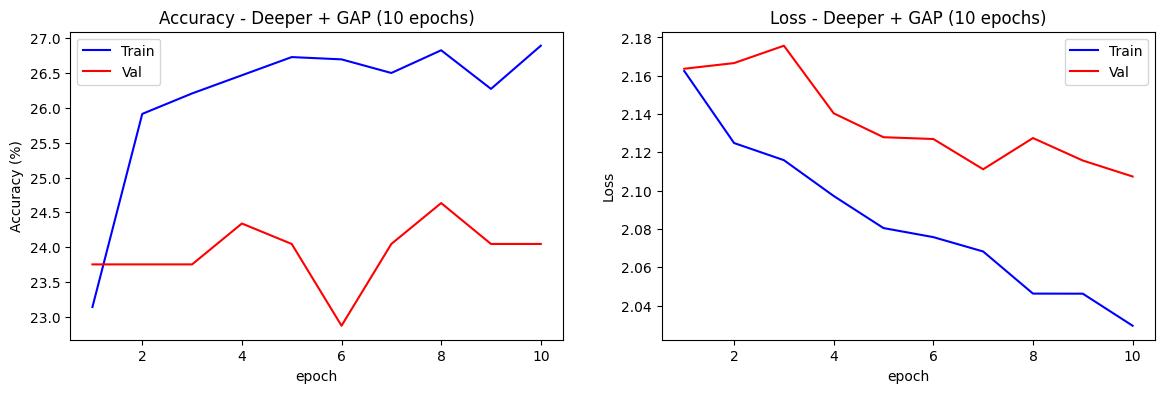

In [ ]:
history = fit(model, train_ds, val_ds, epochs=10)
plot_history(history, "- Deeper + GAP (10 epochs)")

The gap between training and validation curves has largely **disappeared** — but look again: both curves were **still improving** when training stopped. That is a sign of *underfitting* (we stopped too early), not of a finished model.

### Modification #2: train for more epochs

How many epochs? We can't know in advance. We simply train longer and watch the curves. We create a **fresh model** (so we are not continuing from the previous run) and train for 30 epochs.

In [ ]:
set_random_seed(111)
model = CNN().to(device)
history = fit(model, train_ds, val_ds, epochs=30)

Epoch  1/30 - loss: 2.1482 - acc: 0.2516 - val_loss: 2.1599 - val_acc: 0.2375
Epoch  2/30 - loss: 2.1328 - acc: 0.2591 - val_loss: 2.1569 - val_acc: 0.2375
Epoch  3/30 - loss: 2.1232 - acc: 0.2591 - val_loss: 2.1551 - val_acc: 0.2375
Epoch  4/30 - loss: 2.1097 - acc: 0.2621 - val_loss: 2.2172 - val_acc: 0.2375
Epoch  5/30 - loss: 2.1040 - acc: 0.2591 - val_loss: 2.1416 - val_acc: 0.2375
Epoch  6/30 - loss: 2.0861 - acc: 0.2627 - val_loss: 2.1295 - val_acc: 0.2375
Epoch  7/30 - loss: 2.0597 - acc: 0.2650 - val_loss: 2.1518 - val_acc: 0.2375
Epoch  8/30 - loss: 2.0330 - acc: 0.2735 - val_loss: 2.0852 - val_acc: 0.2786
Epoch  9/30 - loss: 1.9870 - acc: 0.3070 - val_loss: 2.0483 - val_acc: 0.3109
Epoch 10/30 - loss: 1.8959 - acc: 0.3654 - val_loss: 1.9248 - val_acc: 0.3372
Epoch 11/30 - loss: 1.7950 - acc: 0.3986 - val_loss: 1.9235 - val_acc: 0.3284
Epoch 12/30 - loss: 1.7507 - acc: 0.4003 - val_loss: 1.8620 - val_acc: 0.3724
Epoch 13/30 - loss: 1.6663 - acc: 0.4254 - val_loss: 1.7600 - va

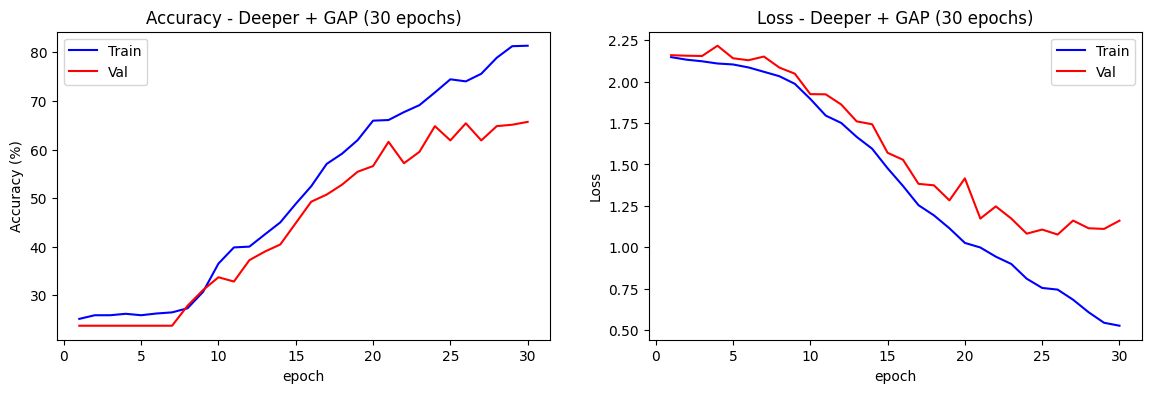


Test accuracy [Deeper + GAP (30 epochs)]: 65.05%


In [ ]:
plot_history(history, "- Deeper + GAP (30 epochs)")
report_test(model, "Deeper + GAP (30 epochs)")

Test accuracy improves substantially compared with the baseline — and with *fewer* parameters. Many more architecture improvements exist (residual connections, NAS, ...), which we will see in later lectures. For now let's add two classic regularizers.

### Modification #3: Batch Normalization + Dropout

- **Batch Normalization** normalizes the activations of a layer (using the mean/variance of the current batch), which stabilizes and speeds up training and adds a slight regularizing noise. We place it between the convolution and the ReLU: `Conv → BatchNorm → ReLU`.
- **Dropout** randomly switches off a fraction of the neurons at each training step (here **50%** in the dense layer), so the network cannot rely on any single neuron. It is active only in `model.train()` mode and disabled in `model.eval()`.

With our flexible class this is just two arguments:

In [ ]:
set_random_seed(111)
model = CNN(use_bn=True, dropout=0.5).to(device)
summary(model, input_size=(1, 3, 128, 128))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [1, 10]                   --
├─Sequential: 1-1                        [1, 256]                  --
│    └─Sequential: 2-1                   [1, 16, 64, 64]           --
│    │    └─Conv2d: 3-1                  [1, 16, 128, 128]         448
│    │    └─BatchNorm2d: 3-2             [1, 16, 128, 128]         32
│    │    └─ReLU: 3-3                    [1, 16, 128, 128]         --
│    │    └─MaxPool2d: 3-4               [1, 16, 64, 64]           --
│    └─Sequential: 2-2                   [1, 32, 32, 32]           --
│    │    └─Conv2d: 3-5                  [1, 32, 64, 64]           4,640
│    │    └─BatchNorm2d: 3-6             [1, 32, 64, 64]           64
│    │    └─ReLU: 3-7                    [1, 32, 64, 64]           --
│    │    └─MaxPool2d: 3-8               [1, 32, 32, 32]           --
│    └─Sequential: 2-3                   [1, 64, 16, 16]           --
│    │    └

Epoch  1/30 - loss: 1.9955 - acc: 0.3266 - val_loss: 1.9392 - val_acc: 0.3314
Epoch  2/30 - loss: 1.6882 - acc: 0.4361 - val_loss: 1.7001 - val_acc: 0.4194
Epoch  3/30 - loss: 1.4621 - acc: 0.5202 - val_loss: 1.7614 - val_acc: 0.3666
Epoch  4/30 - loss: 1.3268 - acc: 0.5606 - val_loss: 2.5127 - val_acc: 0.2405
Epoch  5/30 - loss: 1.2000 - acc: 0.6098 - val_loss: 1.3013 - val_acc: 0.5513
Epoch  6/30 - loss: 1.0514 - acc: 0.6421 - val_loss: 1.2035 - val_acc: 0.5982
Epoch  7/30 - loss: 0.9810 - acc: 0.6643 - val_loss: 1.3800 - val_acc: 0.5660
Epoch  8/30 - loss: 0.8334 - acc: 0.7106 - val_loss: 1.7598 - val_acc: 0.4751
Epoch  9/30 - loss: 0.7978 - acc: 0.7350 - val_loss: 2.0226 - val_acc: 0.3959
Epoch 10/30 - loss: 0.7162 - acc: 0.7487 - val_loss: 1.1274 - val_acc: 0.5836
Epoch 11/30 - loss: 0.6383 - acc: 0.7862 - val_loss: 1.0665 - val_acc: 0.6540
Epoch 12/30 - loss: 0.5387 - acc: 0.8142 - val_loss: 2.1299 - val_acc: 0.3930
Epoch 13/30 - loss: 0.5261 - acc: 0.8243 - val_loss: 1.3776 - va

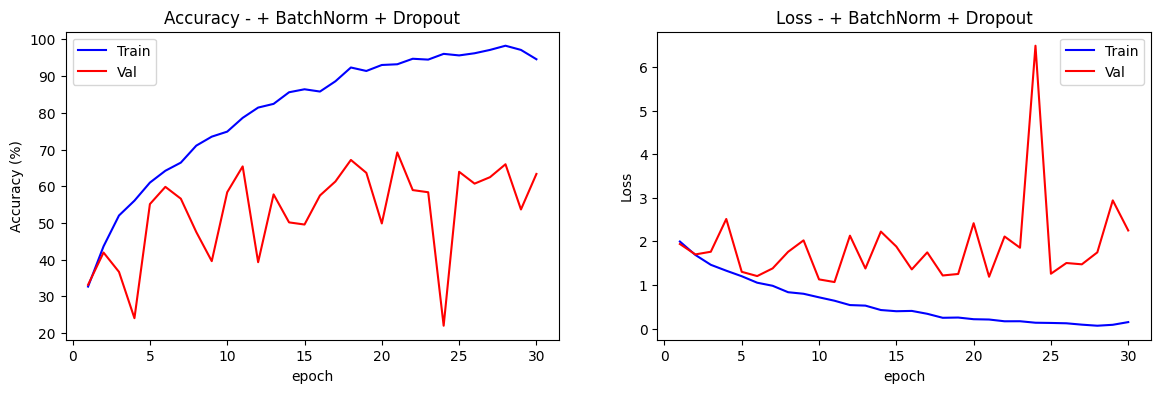

In [ ]:
history = fit(model, train_ds, val_ds, epochs=30)
plot_history(history, "- + BatchNorm + Dropout")

**Something looks off: the curves are very jagged.**

This is partly expected — every regularizer injects randomness into training (dropout switches off 50% of the neurons at random every step) — and our validation set is small (a few hundred images), so its accuracy is naturally noisy. But a *"heartbeat"* pattern is also a typical sign that **the learning rate is too high** near the end of training.

### Modification #4: Learning-rate scheduler + Early stopping

- **`ReduceLROnPlateau`:** when the validation loss has not improved for a while (`patience=5` epochs), multiply the learning rate by 0.3. Big steps early, small careful steps later.
- **Early stopping:** if the validation loss has not improved for `patience=10` epochs, stop training. We don't need to guess the number of epochs any more — we set a generous maximum and let the model tell us when to stop.

**Step 1 — a tiny early-stopping helper:**

In [ ]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.001):
        self.patience, self.min_delta = patience, min_delta
        self.best = float("inf")
        self.bad_epochs = 0
        self.should_stop = False

    def step(self, val_loss):
        if val_loss < self.best - self.min_delta:    # real improvement
            self.best, self.bad_epochs = val_loss, 0
        else:                                        # no improvement
            self.bad_epochs += 1
            if self.bad_epochs >= self.patience:
                self.should_stop = True

**Step 2 — the same `fit` as before with only two additions**, marked with `# NEW`:

In [ ]:
def fit(model, train_loader, val_loader, epochs=10, lr=1e-3, weight_decay=0.0, use_scheduler=False, patience_stop=None):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    # NEW: optional LR scheduler and early stopping
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.3, patience=5, min_lr=1e-5) if use_scheduler else None
    stopper = EarlyStopping(patience=patience_stop) if patience_stop else None

    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    best_val_loss, best_state = float("inf"), None

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = evaluate(model, val_loader, criterion)

        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[k].append(v)

        if va_loss < best_val_loss:
            best_val_loss, best_state = va_loss, copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch:>2}/{epochs} - loss: {tr_loss:.4f} - acc: {tr_acc:.4f} "
              f"- val_loss: {va_loss:.4f} - val_acc: {va_acc:.4f} - lr: {optimizer.param_groups[0]['lr']:.6f}")

        if scheduler: scheduler.step(va_loss)                 # NEW: lower the LR when val loss plateaus
        if stopper:                                            # NEW: stop when val loss stops improving
            stopper.step(va_loss)
            if stopper.should_stop:
                print(f"Early stopping at epoch {epoch}.")
                break

    model.load_state_dict(best_state)
    return history

In [ ]:
set_random_seed(111)
model = CNN(use_bn=True, dropout=0.5).to(device)
history = fit(model, train_ds, val_ds, epochs=60, use_scheduler=True, patience_stop=10)

Epoch  1/60 - loss: 1.9964 - acc: 0.3253 - val_loss: 1.9308 - val_acc: 0.3636 - lr: 0.001000
Epoch  2/60 - loss: 1.6863 - acc: 0.4316 - val_loss: 1.9484 - val_acc: 0.3812 - lr: 0.001000
Epoch  3/60 - loss: 1.4475 - acc: 0.5192 - val_loss: 1.8473 - val_acc: 0.3490 - lr: 0.001000
Epoch  4/60 - loss: 1.2775 - acc: 0.5691 - val_loss: 1.5416 - val_acc: 0.4927 - lr: 0.001000
Epoch  5/60 - loss: 1.1651 - acc: 0.6118 - val_loss: 1.3371 - val_acc: 0.5806 - lr: 0.001000
Epoch  6/60 - loss: 1.0162 - acc: 0.6529 - val_loss: 1.1668 - val_acc: 0.6158 - lr: 0.001000
Epoch  7/60 - loss: 0.9261 - acc: 0.6949 - val_loss: 1.5221 - val_acc: 0.5543 - lr: 0.001000
Epoch  8/60 - loss: 0.8083 - acc: 0.7308 - val_loss: 1.4358 - val_acc: 0.5015 - lr: 0.001000
Epoch  9/60 - loss: 0.7628 - acc: 0.7454 - val_loss: 1.6506 - val_acc: 0.4780 - lr: 0.001000
Epoch 10/60 - loss: 0.6804 - acc: 0.7692 - val_loss: 2.5150 - val_acc: 0.3842 - lr: 0.001000
Epoch 11/60 - loss: 0.5904 - acc: 0.7960 - val_loss: 2.1905 - val_acc:

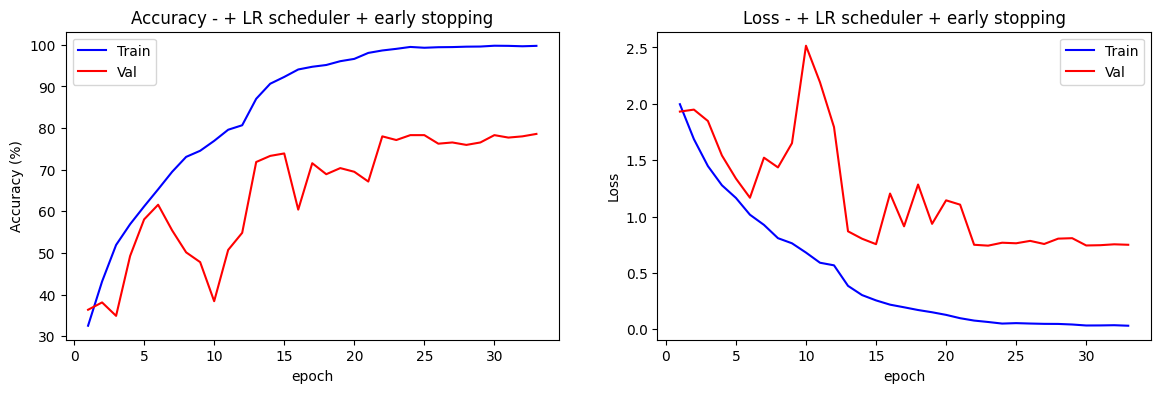


Test accuracy [+ BatchNorm, Dropout, LR schedule, early stop]: 75.00%


In [ ]:
plot_history(history, "- + LR scheduler + early stopping")
report_test(model, "+ BatchNorm, Dropout, LR schedule, early stop")

The curves are smoother and training stopped automatically. Before the break, two observations:
- Each regularizer adds randomness, so training curves get noisier — that is normal.
- Compare the test accuracy with the previous model. Because validation sets are small, differences of one or two points are within noise; look at the overall trend.

# ☕ Break (5 minutes)

### Modification #5: Regularizing the loss — L1 and L2

Another way to stop weights from growing wildly is to add a **penalty on the weights to the loss**:

`total loss = data loss + λ · penalty(weights)`

| | Penalty | Effect |
|---|---|---|
| **L1** (Lasso) | λ · Σ\|w\| | pushes many weights to **exactly 0** → sparse model, acts like feature selection |
| **L2** (Ridge) | λ · Σ w² | shrinks all weights **towards (but not exactly) 0** → small, smooth weights |

*Example — predicting car prices:* L1 may set the weight of an unimportant feature (say, fuel-tank size) to exactly 0, while L2 would keep it but make it small.

**In PyTorch:** the idiomatic way to get L2 is the optimizer's `weight_decay` argument, which shrinks every weight a little on each update. (L1 has no built-in flag; you would add `λ * sum(p.abs().sum() for p in model.parameters())` to the loss yourself.)

> **Implementation notes**
> - With Adam, `weight_decay` adds `weight_decay * w` to the gradient. This is L2 regularization in spirit, but it is *not numerically identical* to Keras' `kernel_regularizer=l2(λ)` (which adds `λ·Σw²` to the loss), and it applies to **all** parameters including biases and BatchNorm parameters.
> - With adaptive optimizers like Adam, the penalty gets rescaled by the adaptive step sizes. **`AdamW`** applies the weight decay in a *decoupled* way and is usually preferred in practice.
> - The right value of the strength is data-dependent; we use a small value, `1e-4`.

In [ ]:
set_random_seed(111)
model = CNN(use_bn=True, dropout=0.5).to(device)
history = fit(model, train_ds, val_ds, epochs=60, use_scheduler=True, patience_stop=10, weight_decay=1e-4)

Epoch  1/60 - loss: 2.0007 - acc: 0.3224 - val_loss: 1.9222 - val_acc: 0.3724 - lr: 0.001000
Epoch  2/60 - loss: 1.6874 - acc: 0.4345 - val_loss: 1.7174 - val_acc: 0.4252 - lr: 0.001000
Epoch  3/60 - loss: 1.4558 - acc: 0.5137 - val_loss: 2.0410 - val_acc: 0.3255 - lr: 0.001000
Epoch  4/60 - loss: 1.2863 - acc: 0.5675 - val_loss: 1.4321 - val_acc: 0.5220 - lr: 0.001000
Epoch  5/60 - loss: 1.1513 - acc: 0.6098 - val_loss: 1.4493 - val_acc: 0.5161 - lr: 0.001000
Epoch  6/60 - loss: 1.0446 - acc: 0.6463 - val_loss: 1.2667 - val_acc: 0.5308 - lr: 0.001000
Epoch  7/60 - loss: 0.9314 - acc: 0.6936 - val_loss: 1.6730 - val_acc: 0.4575 - lr: 0.001000
Epoch  8/60 - loss: 0.8096 - acc: 0.7327 - val_loss: 1.3659 - val_acc: 0.5425 - lr: 0.001000
Epoch  9/60 - loss: 0.7866 - acc: 0.7331 - val_loss: 1.5000 - val_acc: 0.5044 - lr: 0.001000
Epoch 10/60 - loss: 0.6959 - acc: 0.7699 - val_loss: 2.0819 - val_acc: 0.4868 - lr: 0.001000
Epoch 11/60 - loss: 0.5940 - acc: 0.7930 - val_loss: 2.1437 - val_acc:

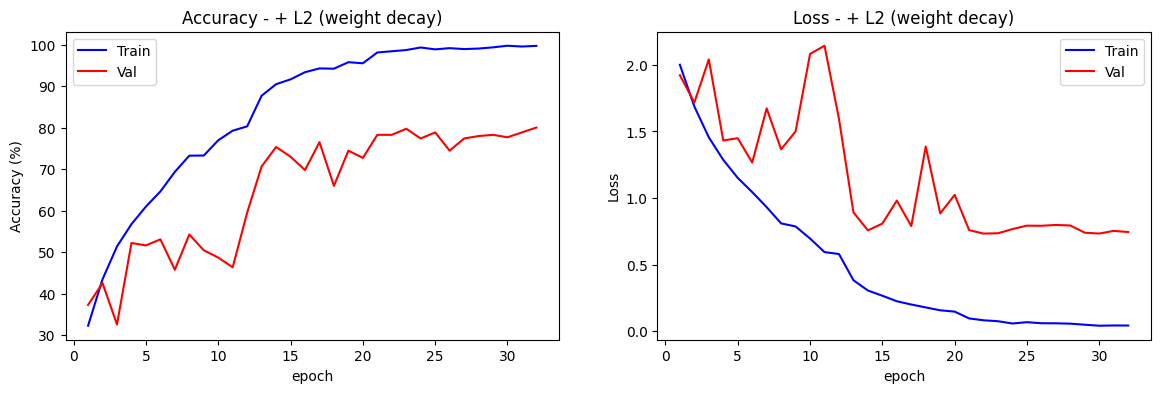


Test accuracy [+ L2 weight decay]: 79.03%


In [ ]:
plot_history(history, "- + L2 (weight decay)")
report_test(model, "+ L2 weight decay")

Compare this test accuracy with the previous run. Weight decay often gives a modest improvement; with a small dataset and an already-regularized network it can also be within noise. Tuning λ on the **validation** set is the right way to decide.

> **🤖 AI Infusion (homework):** ask an AI assistant for the geometric intuition of *why L1 gives sparse weights and L2 does not* (think "diamond vs circle" meeting the loss contours), and *whether Adam's `weight_decay` equals L2 regularization and what AdamW changes*.

# **Quiz 1:** Which of these is true?

a) L1 and L2 regularization are techniques to reduce model complexity and prevent overfitting<br>
b) L2 regularization shrinks the coefficients<br>
c) L1 regularization can also help with feature selection<br>
d) All of the above<br>

**Ans: d)**

Each statement is true. A penalty on the weights makes the model prefer smaller weights, i.e. simpler functions. L1 (Lasso) can drive weights to exactly zero, which removes features; L2 (Ridge) only shrinks them.

## 4. Modifications in the Data Pipeline: Data Augmentation

**Augmentation** artificially increases the amount (and diversity) of training data by generating *new* samples from the existing ones with small, label-preserving changes — flips, shifts, rotations, brightness changes, etc.

<img src='https://drive.google.com/uc?id=15SJ7_ImxN3Ouzdx6T921JtFg0mS0P_Z4' height=200>

**Why it helps:** the model sees a slightly different version of every image in every epoch, so it cannot simply memorize them and must learn features that are robust to these changes.

**Important rules**
- Apply augmentation to the **training set only**. Validation and test sets measure performance on realistic, un-augmented data.
- The augmentation must be **label-preserving and realistic** for your data. (A vertically flipped shirt is not a realistic product photo!)

Common augmentations: flips, rotation, translation, cropping, zooming, brightness/contrast/colour jitter, grayscale, noise, random erasing.

In PyTorch we use `torchvision.transforms` (composable, applied automatically when a sample is requested). For one-off control on a single image there is also `torchvision.transforms.functional` (e.g. `TF.rotate`, `TF.hflip`).

> **🤖 AI Infusion (discussion, 2 min):** describe our dataset (10 clothing classes, seller photos, mostly upright) to an AI assistant and ask which augmentations it recommends and which it warns against. Compare with what you see in the demos below.

**Demo helpers.** We take one image from the training folder and show the original next to 4 random augmented versions.

In [ ]:
def load_sample(size=300):
    cls = "t-shirt" if "t-shirt" in class_names else class_names[0]
    path = sorted(glob.glob(f"{BASE_DIR}/train/{cls}/*"))[0]
    img = Image.open(path).convert("RGB").resize((size, size))
    return transforms.PILToTensor()(img)           # uint8 tensor (3, size, size)

def show_augmented(img, aug, n=4):
    fig, axes = plt.subplots(1, n + 1, figsize=(3 * (n + 1), 3))
    axes[0].imshow(img.permute(1, 2, 0).numpy()); axes[0].set_title("original")
    for ax in axes[1:]:
        ax.imshow(aug(img).permute(1, 2, 0).numpy()); ax.set_title("augmented")
    for ax in axes: ax.axis("off")
    plt.show()

sample = load_sample()

**a. Flips.** `RandomHorizontalFlip` mirrors the image left↔right with probability `p`. Natural for clothing photos. Compare with a vertical flip below.

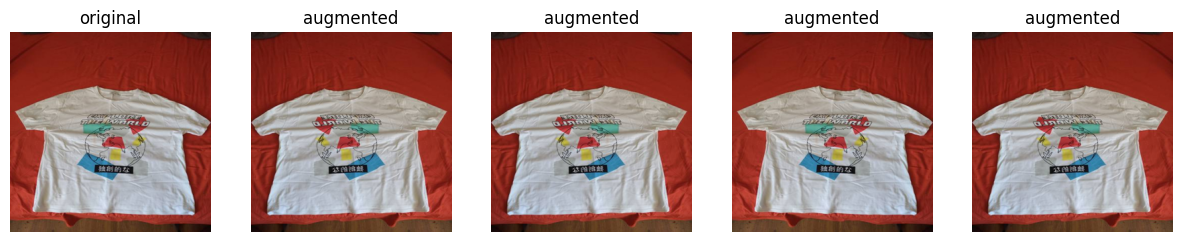

Vertical flip - realistic for product photos? No (collars/sleeves/shoes end up upside down):


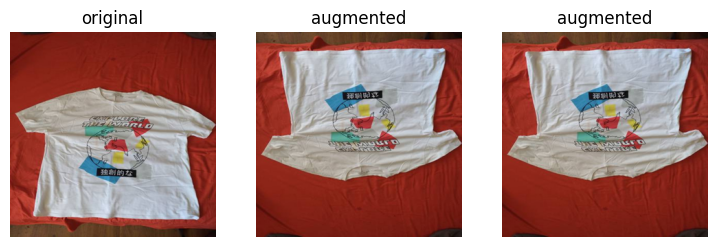

In [ ]:
show_augmented(sample, transforms.RandomHorizontalFlip(p=0.5))
print("Vertical flip - realistic for product photos? No (collars/sleeves/shoes end up upside down):")
show_augmented(sample, transforms.RandomVerticalFlip(p=1.0), n=2)

**b. Rotation.** `RandomRotation` rotates by a random angle in the given range. Keep it *small* for upright products; empty corners are filled with black (`fill`).

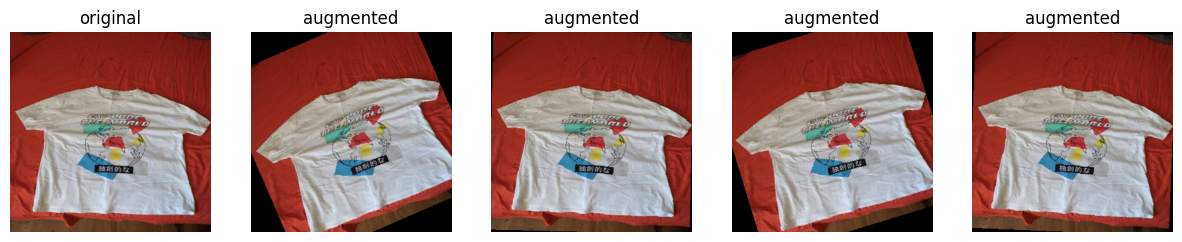

In [ ]:
show_augmented(sample, transforms.RandomRotation(degrees=(-20, 30)))

**c. Translation (shift).** `RandomAffine` can shift (and also rotate/scale/shear) the image. `translate=(0.2, 0.2)` shifts by up to 20% of width/height. This teaches the model that *where* the garment sits in the frame does not matter.

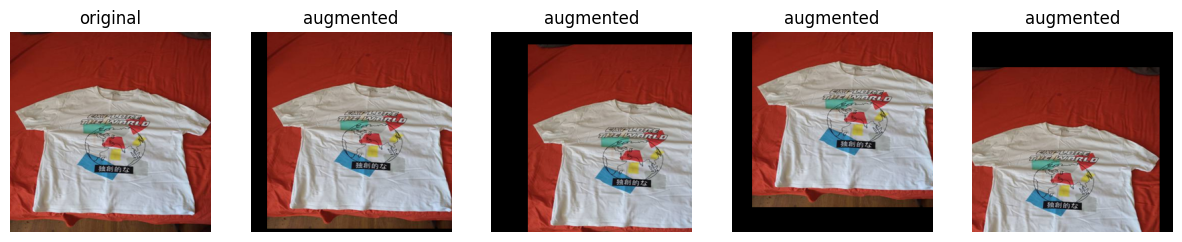

In [ ]:
show_augmented(sample, transforms.RandomAffine(degrees=0, translate=(0.2, 0.2)))

**d. Colour jitter (brightness and contrast).** Simulates different lighting conditions and cameras.

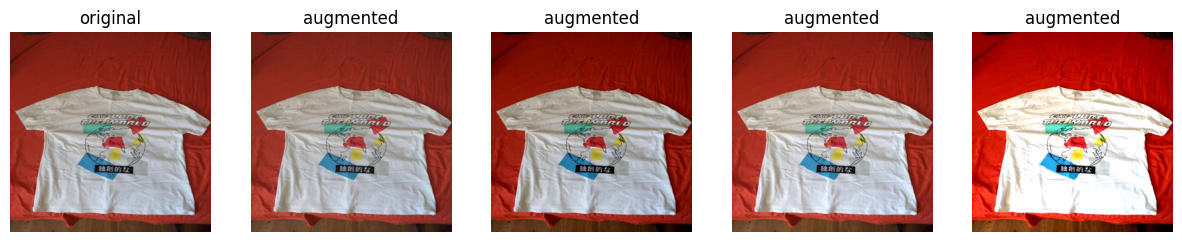

In [ ]:
show_augmented(sample, transforms.ColorJitter(brightness=0.4, contrast=0.4))

# **Quiz 2:** What are the advantages of data augmentation?

a) It prevents underfitting<br>
b) It expands the dataset with realistic variations and helps build a more generalized model<br>
c) Both a) and b)<br>
d) None of the above<br>

**Ans: b)**

Augmentation creates new, varied training examples so the model generalizes better, i.e. it mainly combats **overfitting**. It does not "prevent underfitting" (an underfit model needs more capacity or more training), so a) and c) are false.

### Modification #6: Apply data augmentation to the training pipeline

We combine the safe augmentations from the demos: horizontal flip, a small rotation + translation + slight zoom (one `RandomAffine`), and mild brightness/contrast jitter. They are applied **only** to the training loader through the `augment` argument of our `ClothingDataset`; validation and test data stay untouched.

In [ ]:
train_augment = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
])

train_ds, val_ds, test_ds = make_loaders(train_augment=train_augment)

Let's check what the model will actually see: the **same** training image, drawn 8 times from the augmented training loader.

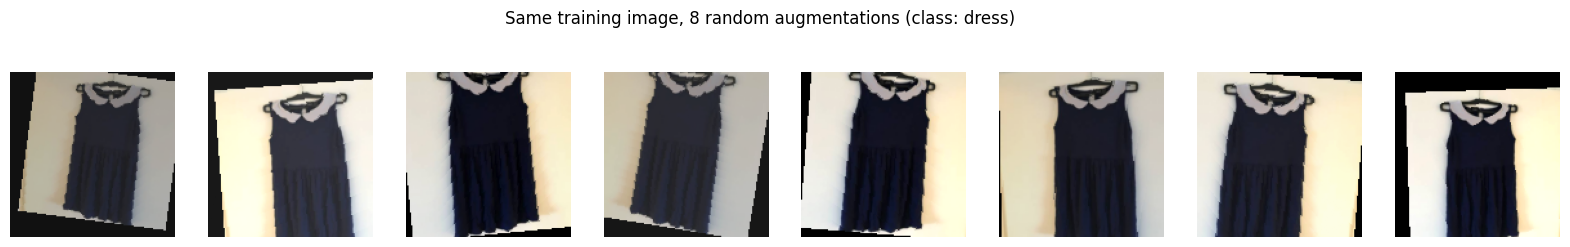

In [ ]:
aug_dataset = train_ds.dataset            # the ClothingDataset used for training
fig, axes = plt.subplots(1, 8, figsize=(20, 3))
for ax in axes:
    img, label = aug_dataset[0]            # same index every time, different random augmentation
    ax.imshow(img.permute(1, 2, 0).numpy()); ax.axis("off")
plt.suptitle(f"Same training image, 8 random augmentations (class: {class_names[label]})"); plt.show()

In [ ]:
set_random_seed(111)
model = CNN(use_bn=True, dropout=0.5).to(device)
history = fit(model, train_ds, val_ds, epochs=60, use_scheduler=True, patience_stop=10, weight_decay=1e-4)

Epoch  1/60 - loss: 2.1144 - acc: 0.2751 - val_loss: 1.9822 - val_acc: 0.3167 - lr: 0.001000
Epoch  2/60 - loss: 1.8877 - acc: 0.3553 - val_loss: 1.8803 - val_acc: 0.3226 - lr: 0.001000
Epoch  3/60 - loss: 1.7533 - acc: 0.4104 - val_loss: 1.7712 - val_acc: 0.3842 - lr: 0.001000
Epoch  4/60 - loss: 1.5945 - acc: 0.4635 - val_loss: 1.7199 - val_acc: 0.4106 - lr: 0.001000
Epoch  5/60 - loss: 1.4971 - acc: 0.4967 - val_loss: 1.5732 - val_acc: 0.4751 - lr: 0.001000
Epoch  6/60 - loss: 1.3989 - acc: 0.5251 - val_loss: 1.5144 - val_acc: 0.5132 - lr: 0.001000
Epoch  7/60 - loss: 1.3085 - acc: 0.5603 - val_loss: 1.6191 - val_acc: 0.4604 - lr: 0.001000
Epoch  8/60 - loss: 1.2257 - acc: 0.5805 - val_loss: 1.2231 - val_acc: 0.5777 - lr: 0.001000
Epoch  9/60 - loss: 1.1928 - acc: 0.6027 - val_loss: 1.1879 - val_acc: 0.5806 - lr: 0.001000
Epoch 10/60 - loss: 1.1117 - acc: 0.6301 - val_loss: 1.2606 - val_acc: 0.5660 - lr: 0.001000
Epoch 11/60 - loss: 1.0772 - acc: 0.6477 - val_loss: 1.3852 - val_acc:

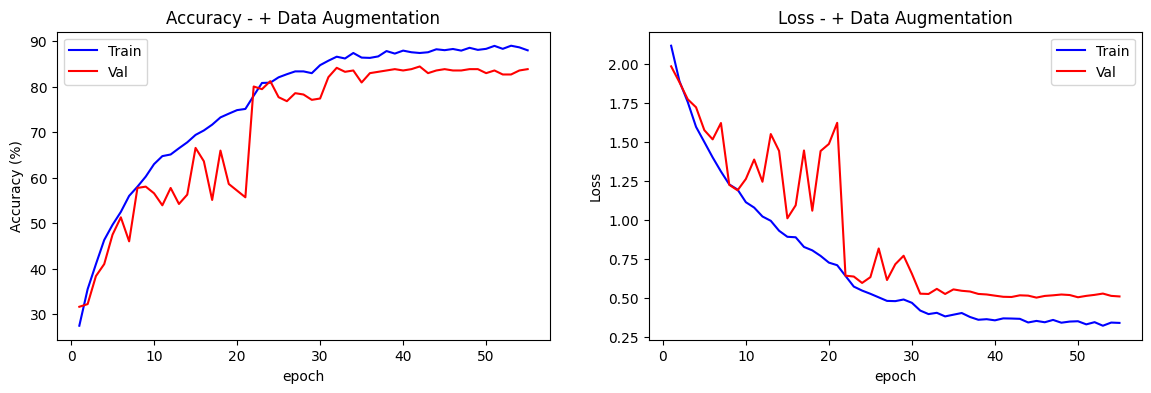


Test accuracy [+ Data augmentation]: 82.53%


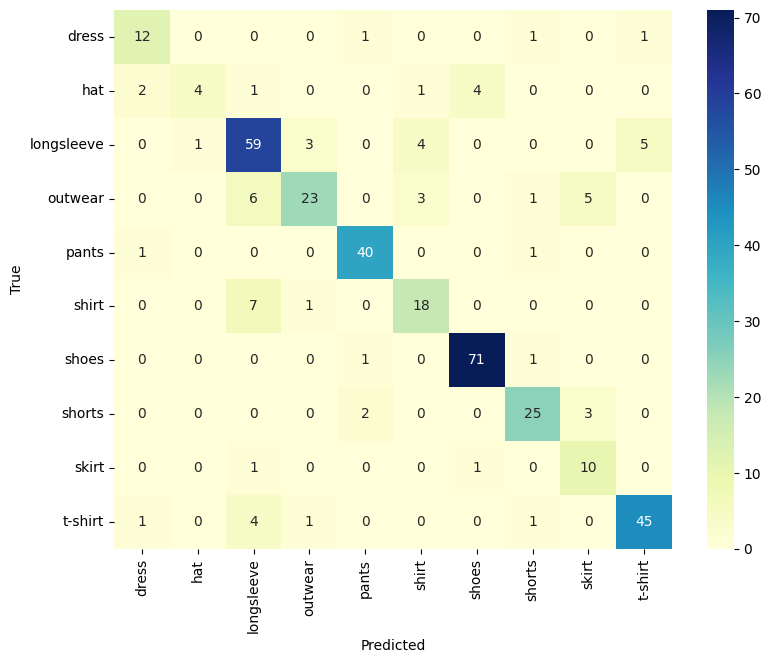

In [ ]:
plot_history(history, "- + Data Augmentation")
report_test(model, "+ Data augmentation", show_cm=True)

With augmentation, the training accuracy no longer races ahead of the validation accuracy, and the validation/test accuracy is typically the best of all our experiments.

**Does augmentation always help?** It helps most when data is limited and the transformations are realistic. Past a certain point, extra synthetic variety stops helping, and unrealistic augmentations (e.g. vertical flips here, or huge rotations) can even hurt.

## 5. Putting it all together

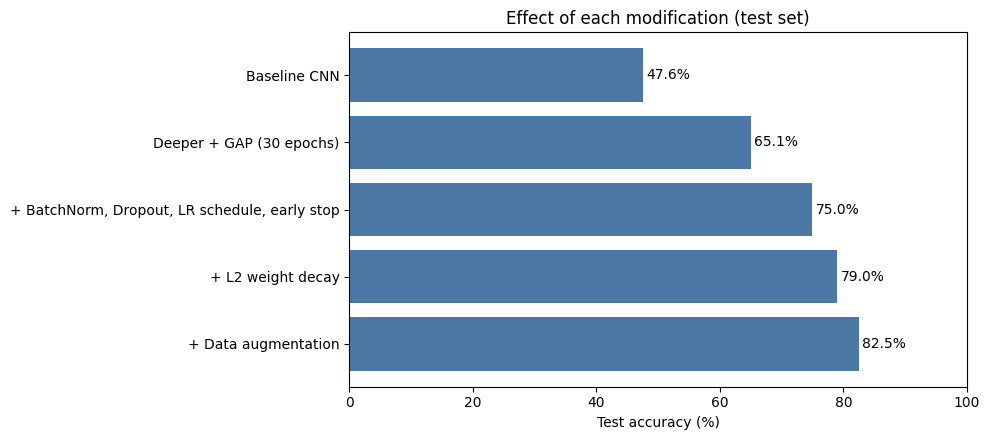

In [ ]:
names, accs = list(results.keys()), list(results.values())
plt.figure(figsize=(10, 4.5))
bars = plt.barh(names[::-1], accs[::-1], color="#4c78a8")
for b, a in zip(bars, accs[::-1]):
    plt.text(a + 0.5, b.get_y() + b.get_height() / 2, f"{a:.1f}%", va="center")
plt.xlabel("Test accuracy (%)"); plt.title("Effect of each modification (test set)")
plt.xlim(0, 100); plt.tight_layout(); plt.show()

Discussion: which single change gave the biggest jump? (Usually: fixing the architecture with GAP + more conv blocks.) Which changes made little difference on their own? Remember — some of these differences are within the noise of a small test set.

## 🤖 AI Infusion: an "AI Training Diagnostician"

We can turn our own training numbers into a well-grounded prompt for an AI assistant — a small example of prompt engineering based on real data.

In [ ]:
def generate_training_diagnosis_prompt(history, model_name="CNN + augmentation"):
    train_acc = history["accuracy"][-1] * 100
    val_acc = history["val_accuracy"][-1] * 100
    best_val_acc = max(history["val_accuracy"]) * 100
    n_epochs = len(history["accuracy"])

    return f"""I trained a CNN ({model_name}) for clothing classification (10 classes) for {n_epochs} epochs.
- Final training accuracy: {train_acc:.2f}%
- Final validation accuracy: {val_acc:.2f}%
- Best validation accuracy: {best_val_acc:.2f}%
- Train-validation gap: {train_acc - val_acc:.2f} points

Is the model overfitting, underfitting, or well balanced? Suggest ONE concrete next step and explain why it beats the alternatives."""

print(generate_training_diagnosis_prompt(history))

I trained a CNN (CNN + augmentation) for clothing classification (10 classes) for 55 epochs.
- Final training accuracy: 88.01%
- Final validation accuracy: 83.87%
- Best validation accuracy: 84.46%
- Train-validation gap: 4.13 points

Is the model overfitting, underfitting, or well balanced? Suggest ONE concrete next step and explain why it beats the alternatives.


> 💡 Paste the printed prompt into an AI assistant and compare its diagnosis with your own reading of the plots.
>
> *Optional (needs an API key):* the same prompt can be sent with the `anthropic` SDK — `client = anthropic.Anthropic()` then `client.messages.create(model="claude-sonnet-5-5", max_tokens=300, messages=[{"role": "user", "content": prompt}])`.

# **Quiz 3:** Which of the following statements are true?

a) Shallow neural networks have only one hidden layer<br>
b) Ridge regression is an example of L1 regularization<br>
c) A Max Pooling layer doesn't have any trainable parameters<br>
d) All of the above<br>

**Ans: a) and c)**

- a) True: shallow networks have a single hidden layer, deep networks have several.
- b) **False:** Ridge regression is L2 regularization; Lasso is L1.
- c) True: max pooling just takes the maximum in each window (forward) and routes the gradient to the position of the maximum (backward). It has nothing to learn.
- d) is therefore false.

# Summary

**How we reduced overfitting, step by step**

| # | Change | Idea |
|---|--------|------|
| 1 | Deeper CNN + Global Average Pooling | far fewer parameters in the dense head |
| 2 | More epochs | the model was still improving (underfit) |
| 3 | BatchNorm + Dropout | stabilize training, add regularizing noise |
| 4 | LR scheduler + Early stopping | smaller steps at the end, stop automatically |
| 5 | L2 regularization (`weight_decay`) | penalize large weights |
| 6 | Data augmentation (training set only) | more diverse data |

**Practice / homework:** (1) try L1 by adding the penalty manually to the loss, (2) swap `Adam` for `AdamW` and compare, (3) tune the augmentation strength, (4) ask an AI assistant for the next architectural improvement to try (residual connections?) and test its suggestion.